#Welcome to my Final project in the last level 😊
The Goal: Uncover the "story" behind my data.

**Phase1 :**


In [ ]:
#import required liraries for data manipulation,visualization,and machine learning

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
#load the dataset from csv file into a pandas dataframe
df=pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [ ]:
#Display the first 5 rows of the dataset to inspect the structure and features
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
#Display concise summary of the dataframe,including column name,non-null counts,and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
#Generate descriptive statistics for numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
#Check for any missing(null)values in each column of the dataset
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
#Convert TotalCharges column to numeric format,forcing any invalid or empty strings to NaN
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')

In [ ]:
# Handle missing values in TotalCharges by filling them with the median
df['TotalCharges']=df['TotalCharges'].fillna(df['TotalCharges'].median())

/tmp/ipykernel_985/3220357768.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn',data=df,palette='Set2')


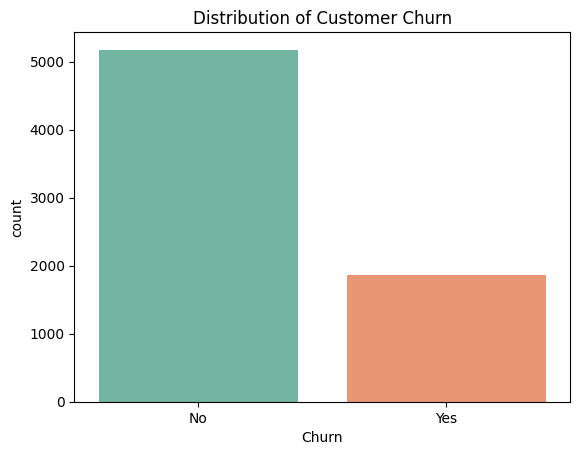

In [ ]:
#Create a count plot to visualize the distribution of customer churn(yes/no)
sns.countplot(x='Churn',data=df,palette='Set2')
plt.title('Distribution of Customer Churn')
plt.show()


* Class Imbalance: The majority of customers stayed with the company (No),
while a smaller portion (~26.5%) churned (Yes).

* Modeling Takeaway: This target variable shows data imbalance, which must be addressed during model training to avoid biased predictions.





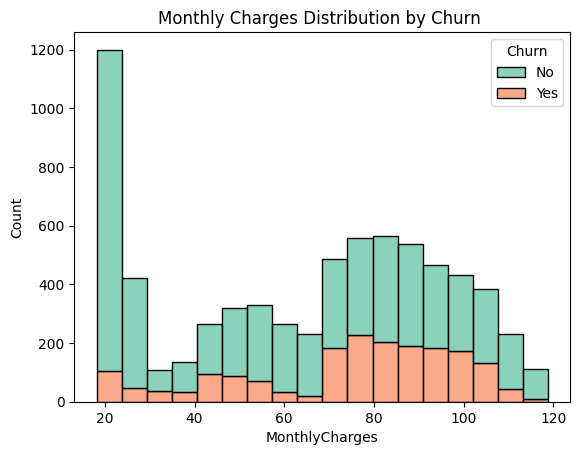

In [ ]:
#Creat a stacked histogram to show the distribution of monthly charges grouped by customer churn
sns.histplot(data=df,x='MonthlyCharges',hue='Churn',multiple='stack',palette='Set2')
plt.title('Monthly Charges Distribution by Churn ')
plt.show()


* Higher Monthly Charges & Churn: Customers with higher monthly charges (specifically between $70 and $100) tend to have a higher proportion of churn (Yes).

* Low-Cost Retention: Customers with lower monthly charges (around $20) show significantly higher

/tmp/ipykernel_985/61354101.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn',y='tenure',data=df,palette='Pastel1')


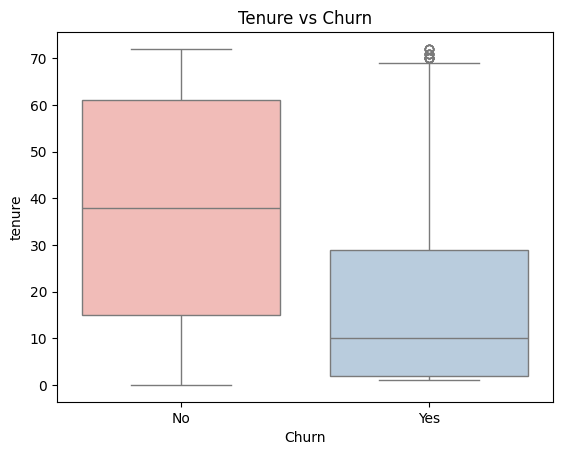

In [ ]:
#Create a box plot to compare the distribution of customer tenure against churn status
sns.boxplot(x='Churn',y='tenure',data=df,palette='Pastel1')
plt.title('Tenure vs Churn')
plt.show()

* Tenure & Churn Relationship: Customers who churned (Yes) tend to have a significantly shorter tenure (lower median) compared to those who stayed (No).

* Loyalty Indicator: Longer subscription periods strongly correlate with higher customer retention and loyalty.



# Phase 2: Pipeline Architecture & Model Training
In this phase, we split the data, construct an automated Pipeline with ColumnTransformer, tune hyperparameters using GridSearchCV, and evaluate model performance.

In [ ]:
# Separate features and target label (drop identifier column)

X = df.drop(columns=['Churn', 'customerID'], errors='ignore')
y = df['Churn'].map({'Yes': 1, 'No': 0})

# Stratified split to preserve class imbalance ratio in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (5634, 19)
Testing set shape: (1409, 19)


In [ ]:
# Identify numerical and categorical features automatically
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
category_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

# Define numerical transformation (Scaling)
num_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Define categorical transformation (One-Hot Encoding)
category_pipeline = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

# Combine feature transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', category_pipeline, category_cols)
])

# Build the complete end-to-end Pipeline with Random Forest
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

In [ ]:
# Define hyperparameter grid for tuning Random Forest inside the pipeline
param_grid={
    "classifier__n_estimators":[50,100,200],
    "classifier__max_depth":[None,10,20],
    "classifier__min_samples_split":[50,100]
}

# Perform 5-fold Cross Validation optimizing for F1-Score due to class imbalance
grid_search=GridSearchCV(
    estimator=full_pipeline,
    param_grid=param_grid,
    cv=5,
    n_jobs=1,
    scoring="f1"
)

# Train grid search on training data
print('Training model with grid search')
grid_search.fit(X_train,y_train)

# Store the best performing model pipeline
best_pipline=grid_search.best_estimator_
print("🌠 Best Parameters Found:",grid_search.best_params_)

Training model with grid search
🌠 Best Parameters Found: {'classifier__max_depth': 10, 'classifier__min_samples_split': 50, 'classifier__n_estimators': 50}


In [ ]:
# Predict target classes on test dataset using the tuned pipeline
y_pred_tuned=best_pipline.predict(X_test)

In [ ]:
# Display classification metrics (Precision, Recall, F1-score)
print("\n--- Tuned Model Classification Report ---")
print(classification_report(y_test, y_pred_tuned))


--- Tuned Model Classification Report ---
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1035
           1       0.67      0.50      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409



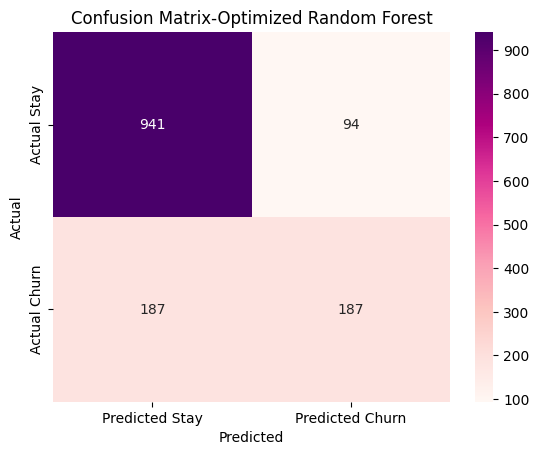

In [ ]:
# Plot Confusion Matrix
cm=confusion_matrix(y_test,y_pred_tuned)
sns.heatmap(cm,annot=True,fmt='d',cmap='RdPu',xticklabels=['Predicted Stay','Predicted Churn'],yticklabels=['Actual Stay','Actual Churn'])
plt.title("Confusion Matrix-Optimized Random Forest")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()